# Stationary vs non-stationary amplitude (ZOIB linking): log Bayes factor and coherence fields

Same layout as `study9-gp-vs-flat-zoib-simple.ipynb`, comparing two models of the Study 9 ratings that differ only in the GP amplitude:

- **stationary:** one amplitude σ₀ everywhere → `results/study9-fit-zoib/posterior.npz`
- **amplitude:** log σ(x) = log σ₀ + wᵀx / s, with w fitted (prior N(0, 0.5²)) and s = 0.197 the pooled coordinate SD → `results/study9-fit-zoib-amp/posterior.npz`

Both use the per-feature ZOIB linking, profiled at each model's own θ. The stationary model is the case w = 0.

In [1]:
DATA_CSV = '../../data/study9_prereg.csv'

import os
os.environ.setdefault("JAX_ENABLE_X64", "1")
import sys
sys.path.insert(0, ".")

import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import plot_style
plot_style.use_lexend()
import inference as inf

OUT = os.path.join('results', 'study9-fit-zoib-amp')
MODEL_SPECS = {'stationary': os.path.join('results', 'study9-fit-zoib', 'posterior.npz'),
               'amplitude':  os.path.join(OUT, 'posterior.npz')}

def _load(path):
    z = np.load(path, allow_pickle=True)
    meta = json.loads(str(z['meta']))
    amp = z['amp_w_samples'] if 'amp_w_samples' in z.files else np.zeros((len(z['ls_samples']), 2))
    return {'ls':    float(np.median(z['ls_samples'])),
            'mu_0':  float(np.median(z['mu0_samples'])),
            'sigma': float(np.median(z['sigma_samples'])),
            'beta':  float(np.median(z['beta_samples'])),
            'amp_w': np.median(amp, axis=0),
            'amp_w_samples': amp,
            'elbo':  float(meta['elbo']),
            'elbo_sd': meta.get('elbo_sd'),
            'status': meta['convergence_status']}

MODELS = {name: _load(p) for name, p in MODEL_SPECS.items()}

geom = inf.load_geometry()
J = geom['J']
S = geom['coord_sd']
responses_cond, _ = inf.load_responses(DATA_CSV, clip_interior=False)    # RAW ratings for the ZOIB
emp_cond = {c: np.array(responses_cond[c]).mean(0) for c in inf.CONDITIONS}
N_cond   = {c: int(responses_cond[c].shape[0]) for c in inf.CONDITIONS}
plt.rcParams.update({'axes.spines.top': False, 'axes.spines.right': False, 'legend.frameon': False})

feat_df = pd.read_pickle('../features/set2_features_dataframe.pkl')
CAT_COLORS = {'physical': 'tab:red', 'diet_preferences': 'tab:green', 'personality_behaviors': 'tab:blue'}
cent = {c: feat_df.loc[feat_df.category == c, ['x_2d', 'y_2d']].values.mean(0) for c in CAT_COLORS}
U_AWAY = -cent['physical'] / np.linalg.norm(cent['physical'])
d = cent['diet_preferences'] - cent['personality_behaviors']
U_BOTH = np.array([d[1], -d[0]]) / np.linalg.norm(d)
U_BOTH = U_BOTH if cent['physical'] @ U_BOTH < 0 else -U_BOTH

## 1. log Z per model and the log Bayes factor

**log Z (VBMC ELBO)** for each model integrates over θ under its priors, so the amplitude model already pays for its 2 extra parameters. **log BF** = log Z_amplitude − log Z_stationary; a value > 0 favours the amplitude model. The thresholds (Kass & Raftery, natural log) are: < 1.1 barely worth mentioning, 1.1–3 positive, 3–5 strong.

The plug-in Laplace log Z at each posterior-median θ is shown too. θ is held fixed there, so it doesn't pay for the extra parameters.

In [2]:
plugin = {name: inf.total_log_lik_zoib(geom, responses_cond, m['ls'], m['mu_0'], m['sigma'],
                                       beta_speaker=m['beta'], amp_w=m['amp_w'])
          for name, m in MODELS.items()}

print(f"{'model':<12}{'ls':>7}{'mu_0':>8}{'sigma':>8}{'beta':>8}{'amp_w':>18}{'log Z (ELBO)':>15}{'ELBO sd':>9}"
      f"{'plug-in log Z':>15}  status")
for name, m in MODELS.items():
    sd = f"{m['elbo_sd']:.2f}" if m['elbo_sd'] is not None else 'n/a'
    w = '(' + ', '.join(f'{v:+.2f}' for v in m['amp_w']) + ')'
    print(f"{name:<12}{m['ls']:>7.3g}{m['mu_0']:>+8.3f}{m['sigma']:>8.3f}{m['beta']:>8.2f}{w:>18}"
          f"{m['elbo']:>15.2f}{sd:>9}{float(plugin[name]):>15.2f}  {m['status']}")

log_bf = MODELS['amplitude']['elbo'] - MODELS['stationary']['elbo']
sds = [MODELS[n]['elbo_sd'] for n in MODELS]
bf_sd = None if None in sds else float(np.hypot(*sds))
print(f"\nlog BF (amplitude vs stationary) = {log_bf:+.2f}" + (f"  ± {bf_sd:.2f}" if bf_sd is not None else
      "   (stationary run predates elbo_sd)"))
print(f"plug-in log LR (no Occam)        = {float(plugin['amplitude']) - float(plugin['stationary']):+.2f}")

model            ls    mu_0   sigma    beta             amp_w   log Z (ELBO)  ELBO sd  plug-in log Z  status
stationary    0.344  +1.293   0.522   25.93    (+0.00, +0.00)       -1724.91      n/a       -1719.89  probable
amplitude     0.325  +1.428   0.437   25.78    (-0.21, -0.02)       -1725.76     0.18       -1717.88  probable

log BF (amplitude vs stationary) = -0.84   (stationary run predates elbo_sd)
plug-in log LR (no Occam)        = +2.01


## 2. Posterior over w

Each dot is one posterior sample of w. The dashed circle is the prior's 95% region, N(0, 0.5²) on each axis. Arrows show the two causal-hypothesis directions, where σ is lowest at physical. A posterior concentrated along an arrow would mean the data favour that direction.

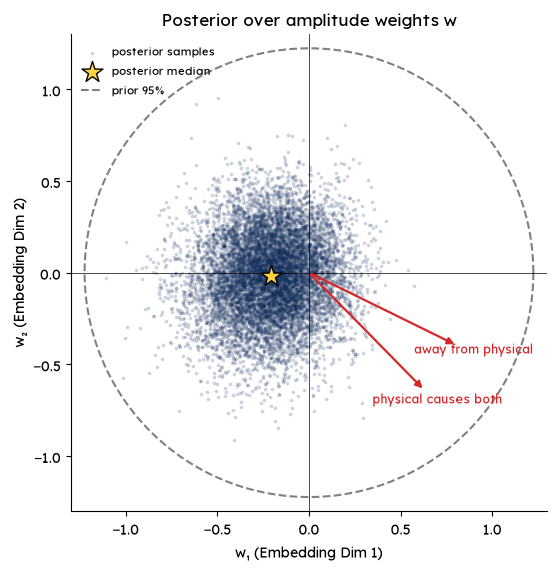

w1: median -0.206, 95% [-0.63, +0.19], P(w1 > 0) = 0.15
w2: median -0.016, 95% [-0.47, +0.42], P(w2 > 0) = 0.47


In [3]:
W = MODELS['amplitude']['amp_w_samples']
fig, ax = plt.subplots(figsize=(5.8, 5.6), layout='constrained')
ax.scatter(W[:, 0], W[:, 1], s=3, alpha=0.15, color='#16305e', label='posterior samples')
ax.scatter(*np.median(W, 0), marker='*', s=250, color='#ffd23f', edgecolor='k', zorder=4, label='posterior median')
t = np.linspace(0, 2 * np.pi, 200)
r95 = inf.AMP_PRIOR_SD * np.sqrt(-2 * np.log(0.05))      # 95% radius of an isotropic 2D normal
ax.plot(r95 * np.cos(t), r95 * np.sin(t), '--', color='grey', label='prior 95%')
for name, u in [('away from physical', U_AWAY), ('physical causes both', U_BOTH)]:
    ax.annotate('', xy=0.9 * u, xytext=(0, 0), arrowprops=dict(arrowstyle='-|>', color='tab:red', lw=1.6))
    ax.text(*(1.0 * u), name, color='tab:red', fontsize=9, ha='center')
ax.axhline(0, color='k', lw=0.5); ax.axvline(0, color='k', lw=0.5)
ax.set_xlim(-1.3, 1.3); ax.set_ylim(-1.3, 1.3); ax.set_aspect('equal')
ax.set_xlabel('w₁ (Embedding Dim 1)'); ax.set_ylabel('w₂ (Embedding Dim 2)')
ax.legend(fontsize=8, loc='upper left')
ax.set_title('Posterior over amplitude weights w')
fig.savefig(os.path.join(OUT, 'amp-w-posterior.png'), dpi=150, bbox_inches='tight')
plt.show()
for k in range(2):
    lo, hi = np.percentile(W[:, k], [2.5, 97.5])
    print(f"w{k + 1}: median {np.median(W[:, k]):+.3f}, 95% [{lo:+.2f}, {hi:+.2f}], P(w{k + 1} > 0) = {np.mean(W[:, k] > 0):.2f}")

## 3. The fitted amplitude field σ(x)

σ(x) at the posterior-median w over the embedding, on a log colour scale centred on σ₀. All 60 features are shown, coloured by category, with ○ for train and ▲ for test.

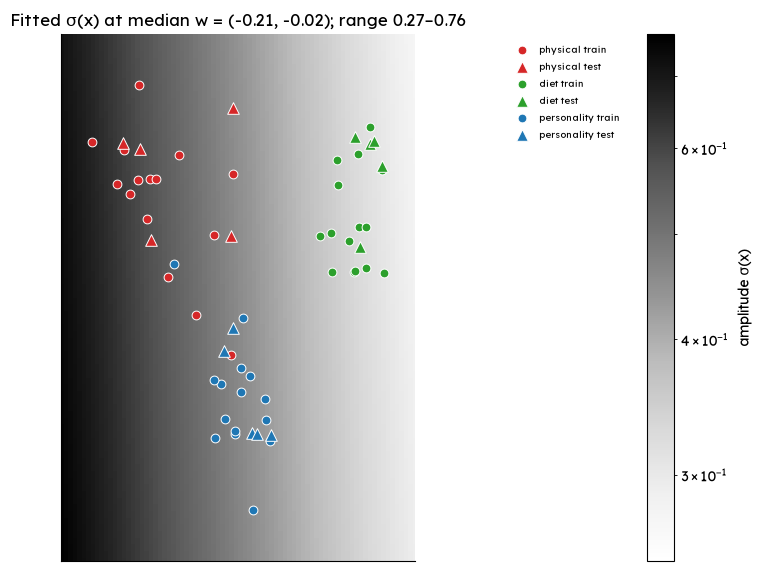

σ at physical               centroid: 0.551
σ at diet_preferences       centroid: 0.327
σ at personality_behaviors  centroid: 0.462


In [4]:
from matplotlib.colors import LogNorm
all_x = np.vstack([np.array(geom['x_test'])] + [np.array(geom['x_train_cond'][c]) for c in inf.CONDITIONS])
pad = 0.08
(x_lo, y_lo), (x_hi, y_hi) = all_x.min(0) - pad, all_x.max(0) + pad
gx, gy = np.meshgrid(np.linspace(x_lo, x_hi, 80), np.linspace(y_lo, y_hi, 80))
X_grid = np.column_stack([gx.ravel(), gy.ravel()])
x_test_np = np.array(geom['x_test'])

m = MODELS['amplitude']
sig_grid = np.asarray(inf.amplitude(X_grid, m['sigma'], np.asarray(m['amp_w']), S)).reshape(gx.shape)
ratio = max(sig_grid.max() / m['sigma'], m['sigma'] / sig_grid.min())
fig, ax = plt.subplots(figsize=(7, 5.6), layout='constrained')
im = ax.pcolormesh(gx, gy, sig_grid, cmap='Greys', shading='auto',
                   norm=LogNorm(vmin=m['sigma'] / ratio, vmax=m['sigma'] * ratio))
fig.colorbar(im, ax=ax, label='amplitude σ(x)')
for cat, col in CAT_COLORS.items():
    for split, mk in [('train', 'o'), ('test', '^')]:
        pts = feat_df.loc[(feat_df.category == cat) & (feat_df.split == split), ['x_2d', 'y_2d']].values
        ax.scatter(pts[:, 0], pts[:, 1], marker=mk, s=40 if split == 'train' else 70, color=col,
                   edgecolor='white', lw=0.7, zorder=3, label=f"{cat.split('_')[0]} {split}")
ax.set_xlim(x_lo, x_hi); ax.set_ylim(y_lo, y_hi); ax.set_xticks([]); ax.set_yticks([])
ax.legend(fontsize=7, loc='upper left', bbox_to_anchor=(1.25, 1))
ax.set_title(f"Fitted σ(x) at median w = ({m['amp_w'][0]:+.2f}, {m['amp_w'][1]:+.2f}); "
             f"range {sig_grid.min():.2f}–{sig_grid.max():.2f}")
fig.savefig(os.path.join(OUT, 'amp-sigma-field.png'), dpi=150, bbox_inches='tight')
plt.show()
for cat in CAT_COLORS:
    print(f"σ at {cat:<22} centroid: {float(inf.amplitude(cent[cat][None], m['sigma'], np.asarray(m['amp_w']), S)[0]):.3f}")

## 4. Coherence fields: one colour scale, shared across models

One row per model and one column per condition. The background is the GP coherence field P(kind-linked) at the model's posterior-median θ (and w, for the amplitude model). **Both rows share the same coherence range.**

Test features (circles) are filled by their empirical mean prevalence rating, using the same colormap on the ratings' own range. The colorbar shows coherence on the left and mean rating on the right.

In [5]:
fields, field_at_test = {}, {}
for name, m in MODELS.items():
    for c in inf.CONDITIONS:
        fields[name, c] = inf.gp_coherence_field(geom, c, m['ls'], m['mu_0'], m['sigma'], X_grid,
                                                 beta_speaker=m['beta'], amp_w=m['amp_w']).reshape(gx.shape)
        field_at_test[name, c] = inf.gp_coherence_field(geom, c, m['ls'], m['mu_0'], m['sigma'], x_test_np,
                                                        beta_speaker=m['beta'], amp_w=m['amp_w'])

f_all = np.stack(list(fields.values()))
COH_LO, COH_HI = float(f_all.min()), float(f_all.max())
RAT_LO = min(e.min() for e in emp_cond.values())
RAT_HI = max(e.max() for e in emp_cond.values())
LEVELS = np.linspace(COH_LO, COH_HI, 21)
CMAP = 'Blues'
print(f"coherence range (both models): [{COH_LO:.3f}, {COH_HI:.3f}]")
print(f"mean-rating range:             [{RAT_LO:.3f}, {RAT_HI:.3f}]")
for name in MODELS:
    spread = [np.ptp(fields[name, c]) for c in inf.CONDITIONS]
    print(f"  {name:<11} within-condition field spread: " + ", ".join(f"{s:.4f}" for s in spread))

coherence range (both models): [0.787, 0.858]
mean-rating range:             [0.352, 0.766]
  stationary  within-condition field spread: 0.0555, 0.0586, 0.0532, 0.0419
  amplitude   within-condition field spread: 0.0500, 0.0285, 0.0419, 0.0328


saved results/study9-fit-zoib-amp/coherence-field-fig-shared-scale.png


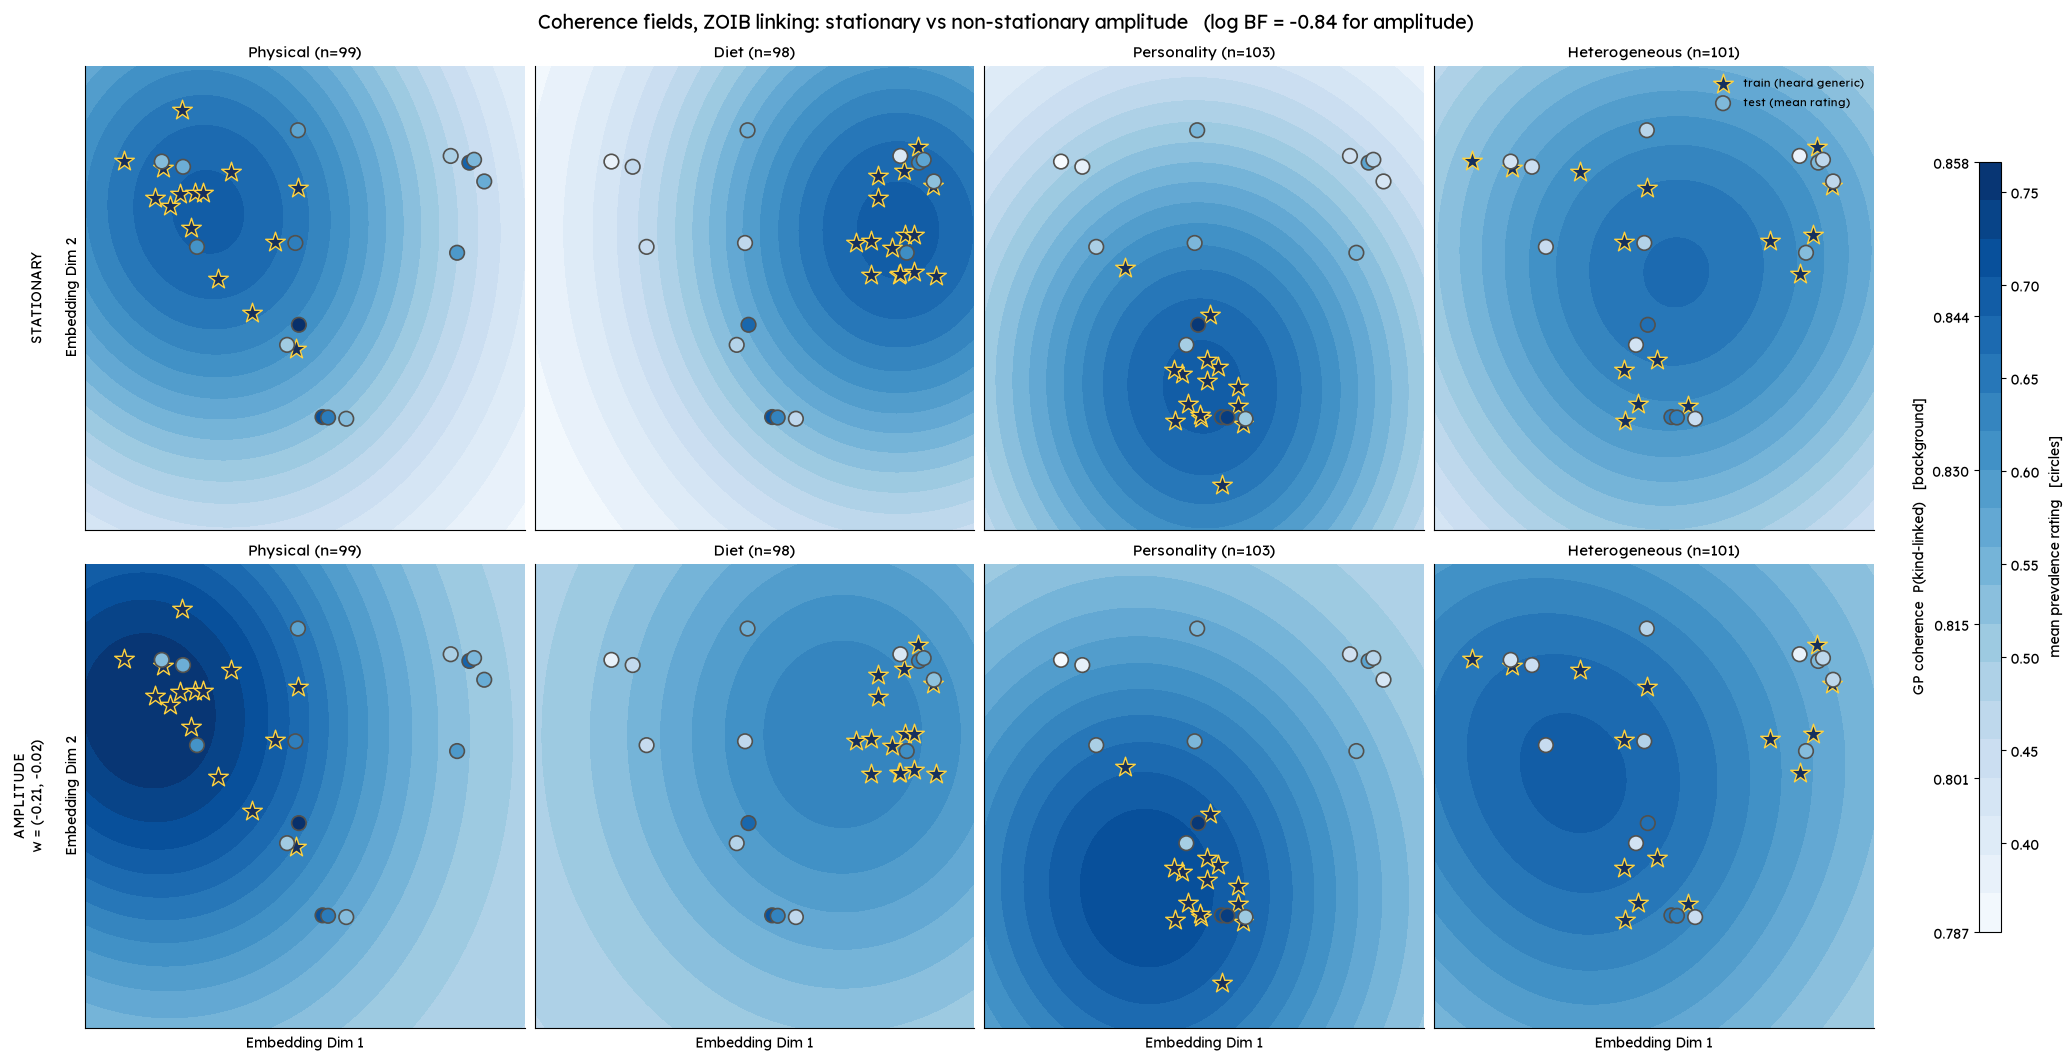

In [6]:
def _colorbar(fig, cs, axes):
    cb = fig.colorbar(cs, ax=axes, location='right', shrink=0.8, aspect=35, pad=0.02)
    cb.set_ticks(np.linspace(COH_LO, COH_HI, 6), labels=[f'{v:.3f}' for v in np.linspace(COH_LO, COH_HI, 6)])
    cb.ax.yaxis.set_ticks_position('left'); cb.ax.yaxis.set_label_position('left')
    cb.set_label('GP coherence  P(kind-linked)   [background]')
    cb_r = cb.ax.twinx()
    cb_r.set_ylim(RAT_LO, RAT_HI)
    cb_r.set_ylabel('mean prevalence rating   [circles]')
    for s in cb_r.spines.values():
        s.set_visible(False)

def _panel(ax, name, c, edge='#52514e'):
    cs = ax.contourf(gx, gy, fields[name, c], levels=LEVELS, cmap=CMAP)
    x_tr = np.array(geom['x_train_cond'][c])
    ax.scatter(x_tr[:, 0], x_tr[:, 1], s=220, marker='*', color='#16305e', edgecolor='#ffd23f', lw=1.0,
               zorder=3, label='train (heard generic)')
    ax.scatter(x_test_np[:, 0], x_test_np[:, 1], s=110, c=emp_cond[c], cmap=CMAP, vmin=RAT_LO, vmax=RAT_HI,
               edgecolor=edge, linewidth=1.2, zorder=4, label='test (mean rating)')
    ax.set_xlim(x_lo, x_hi); ax.set_ylim(y_lo, y_hi)
    ax.set_xticks([]); ax.set_yticks([])
    ax.set_title(f"{c.capitalize()} (n={N_cond[c]})", fontsize=11)
    return cs

fig, axes = plt.subplots(len(MODELS), len(inf.CONDITIONS), figsize=(20, 10.5), layout='constrained')
for row, (name, m) in enumerate(MODELS.items()):
    for col, c in enumerate(inf.CONDITIONS):
        cs = _panel(axes[row, col], name, c)
        if col == 0:
            w_txt = '' if name == 'stationary' else f"\nw = ({m['amp_w'][0]:+.2f}, {m['amp_w'][1]:+.2f})"
            axes[row, col].set_ylabel(f"{name.upper()}{w_txt}\n\nEmbedding Dim 2")
        if row == len(MODELS) - 1:
            axes[row, col].set_xlabel('Embedding Dim 1')
axes[0, -1].legend(fontsize=8, loc='upper right')
_colorbar(fig, cs, axes)
fig.suptitle(f"Coherence fields, ZOIB linking: stationary vs non-stationary amplitude   "
             f"(log BF = {log_bf:+.2f} for amplitude)", fontsize=14)
out_png = os.path.join(OUT, 'coherence-field-fig-shared-scale.png')
fig.savefig(out_png, dpi=150, bbox_inches='tight')
print('saved', out_png)
plt.show()

### 4b. One figure per fit, 2×2

The section 4 figure split into one 2×2 figure per model, with the same shared scales. Saved to `results/study9-fit-zoib-amp/coherence-field-fig-shared-scale-<model>.png`.

saved results/study9-fit-zoib-amp/coherence-field-fig-shared-scale-stationary.png


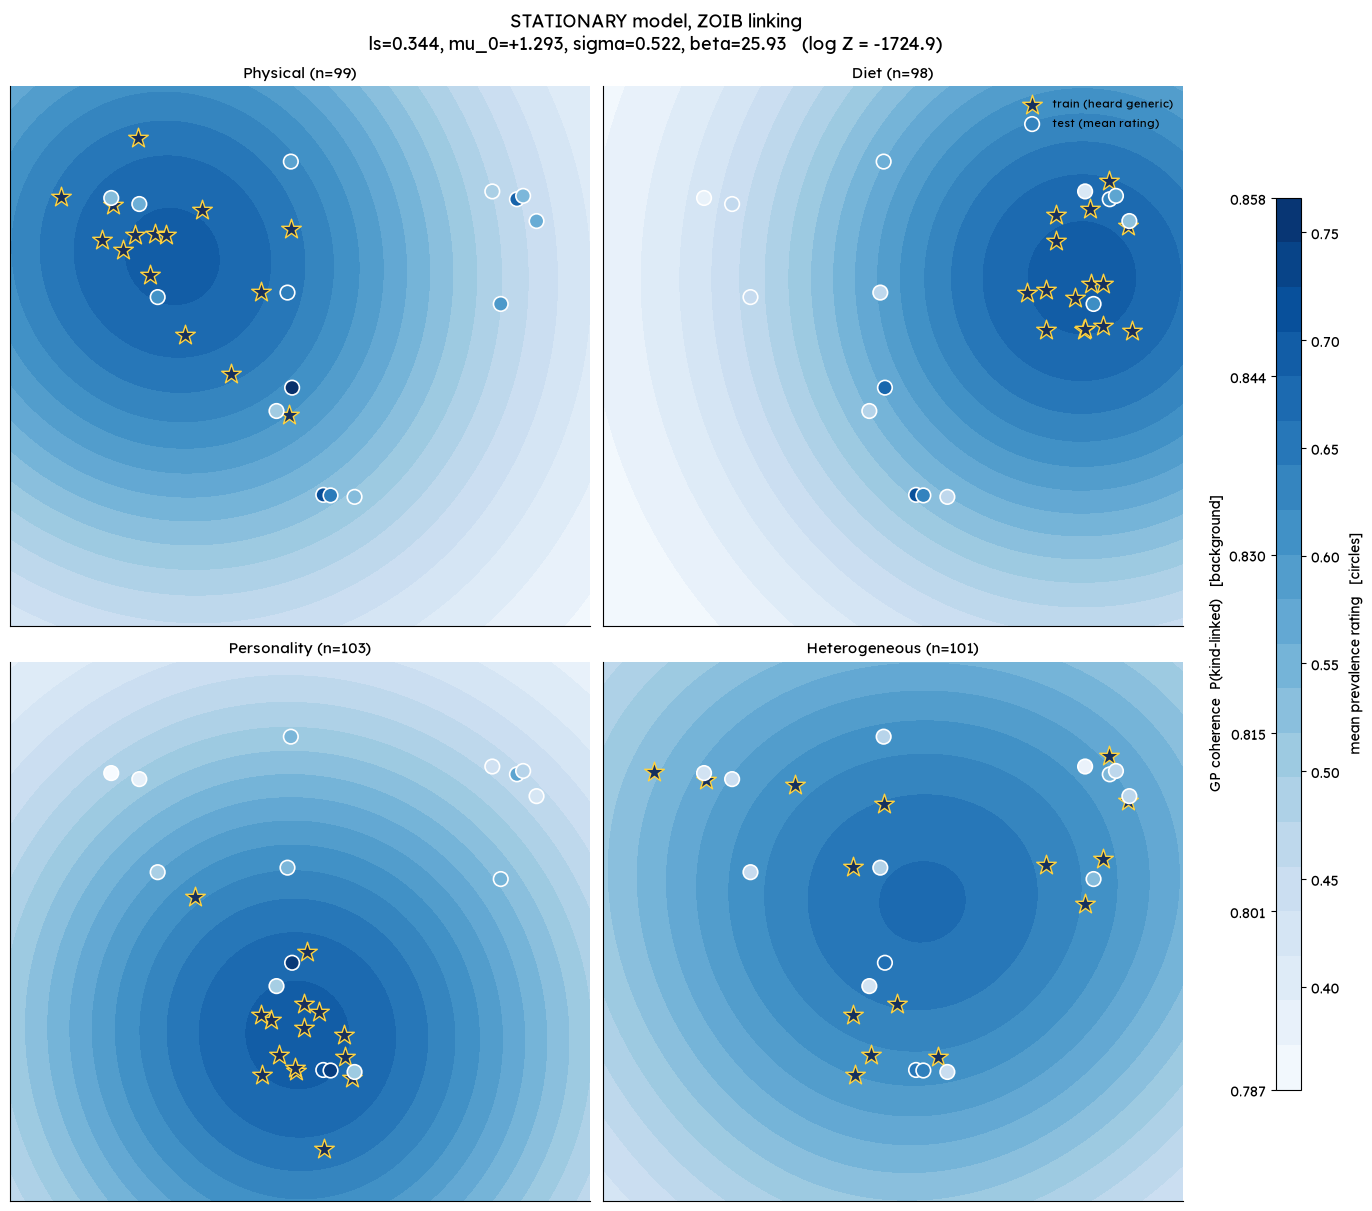

saved results/study9-fit-zoib-amp/coherence-field-fig-shared-scale-amplitude.png


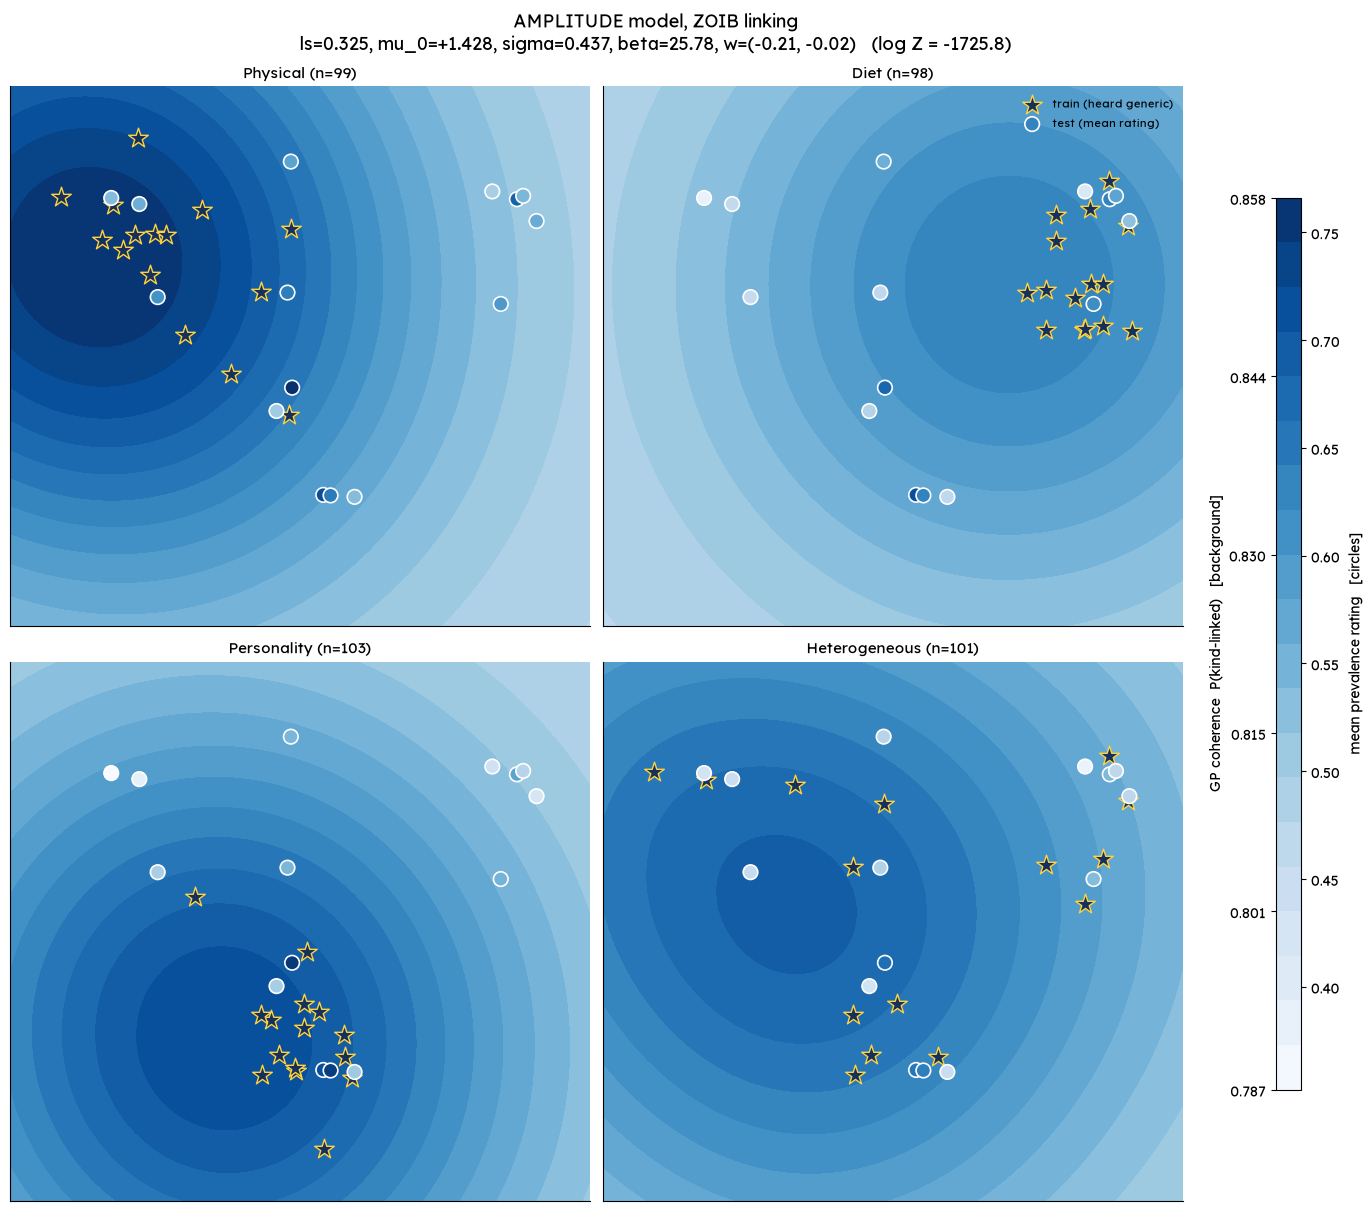

In [7]:
for name, m in MODELS.items():
    fig, axes = plt.subplots(2, 2, figsize=(13, 12), layout='constrained')
    for ax, c in zip(axes.ravel(), inf.CONDITIONS):
        cs = _panel(ax, name, c, edge='#ffffff')
    axes[0, 1].legend(fontsize=8, loc='upper right')
    _colorbar(fig, cs, axes)
    w_txt = '' if name == 'stationary' else f", w=({m['amp_w'][0]:+.2f}, {m['amp_w'][1]:+.2f})"
    fig.suptitle(f"{name.upper()} model, ZOIB linking\n"
                 f"ls={m['ls']:.3g}, mu_0={m['mu_0']:+.3f}, sigma={m['sigma']:.3f}, beta={m['beta']:.2f}{w_txt}   "
                 f"(log Z = {m['elbo']:.1f})", fontsize=13)
    out_png = os.path.join(OUT, f'coherence-field-fig-shared-scale-{name}.png')
    fig.savefig(out_png, dpi=150, bbox_inches='tight')
    print('saved', out_png)
    plt.show()

## 5. Predicted vs empirical prevalence per feature

One row of four condition panels per model. Each point is a test feature, coloured by its category (physical red, diet green, personality blue), with the matched-condition category outlined in black. x is the empirical mean rating, y is the model's E[rating], and the dashed line is the identity. Panel titles give the per-condition r, and the row label gives the pooled r. Predictions come from each fit's `predictions.csv`, at its posterior-median θ.

There are two versions:
- **5a, ratings-conditioned** (`pred_posterior`, as in `study9-gp-vs-flat-zoib.ipynb`): the coherence mode after also seeing the ratings, pushed through the linking.
- **5b, generics only** (`pred_prior`): the ratings-free coherence, i.e. what the learner predicts from the generics alone, pushed through the linking. This is the honest generalization prediction. Its differences across conditions are what section 4's fields show.

In [8]:
PRED_FILES = {'stationary': os.path.join('results', 'study9-fit-zoib', 'predictions.csv'),
              'amplitude':  os.path.join(OUT, 'predictions.csv')}
TRAIT_COLOR = {'physical': 'tab:red', 'diet': 'tab:green', 'personality': 'tab:blue'}
traits = np.array(geom['test_trait'])
preds = {}
for name, path in PRED_FILES.items():
    df_p = pd.read_csv(path)
    preds[name] = {col: {c: df_p[df_p.key == c].set_index('feature').loc[geom['test_feature_names'], col].values
                         for c in inf.CONDITIONS} for col in ['pred_posterior', 'pred_prior']}
emp_all = np.concatenate([emp_cond[c] for c in inf.CONDITIONS])

def scatter_fig(col, title, fname):
    fig, axgrid = plt.subplots(len(MODELS), len(inf.CONDITIONS), figsize=(4.2 * len(inf.CONDITIONS), 4.2 * len(MODELS)),
                               sharex=True, sharey=True)
    for row, name in enumerate(MODELS):
        pred_cond = preds[name][col]
        for k, c in enumerate(inf.CONDITIONS):
            ax = axgrid[row, k]
            for tr, colr in TRAIT_COLOR.items():
                mask = traits == tr
                ax.scatter(emp_cond[c][mask], pred_cond[c][mask], s=70, color=colr,
                           edgecolor=('k' if tr == c else 'none'), linewidth=1.5,
                           label=tr if (row == 0 and k == 0) else None)
            ax.plot([0, 1], [0, 1], '--', color='gray', alpha=0.5)
            ax.set_xlim(0, 1); ax.set_ylim(0, 1)
            r = np.corrcoef(pred_cond[c], emp_cond[c])[0, 1]
            ax.set_title(f"{c}  r={r:+.3f}", fontsize=9)
            if k == 0:
                r_pool = np.corrcoef(np.concatenate([pred_cond[cc] for cc in inf.CONDITIONS]), emp_all)[0, 1]
                ax.set_ylabel(f"{name}\n(pooled r={r_pool:+.3f})\npredicted E[rating]", fontsize=9)
            if row == len(MODELS) - 1:
                ax.set_xlabel('empirical mean')
    axgrid[0, 0].legend(fontsize=8, title='test trait', loc='upper left')
    fig.suptitle(title, fontsize=13, y=0.995)
    plt.tight_layout(rect=[0, 0, 1, 0.985])
    out_png = os.path.join(OUT, fname)
    fig.savefig(out_png, dpi=150, bbox_inches='tight')
    print('saved', out_png)
    plt.show()

### 5a. Ratings-conditioned prediction

saved results/study9-fit-zoib-amp/predicted-vs-empirical-scatter-comparison.png


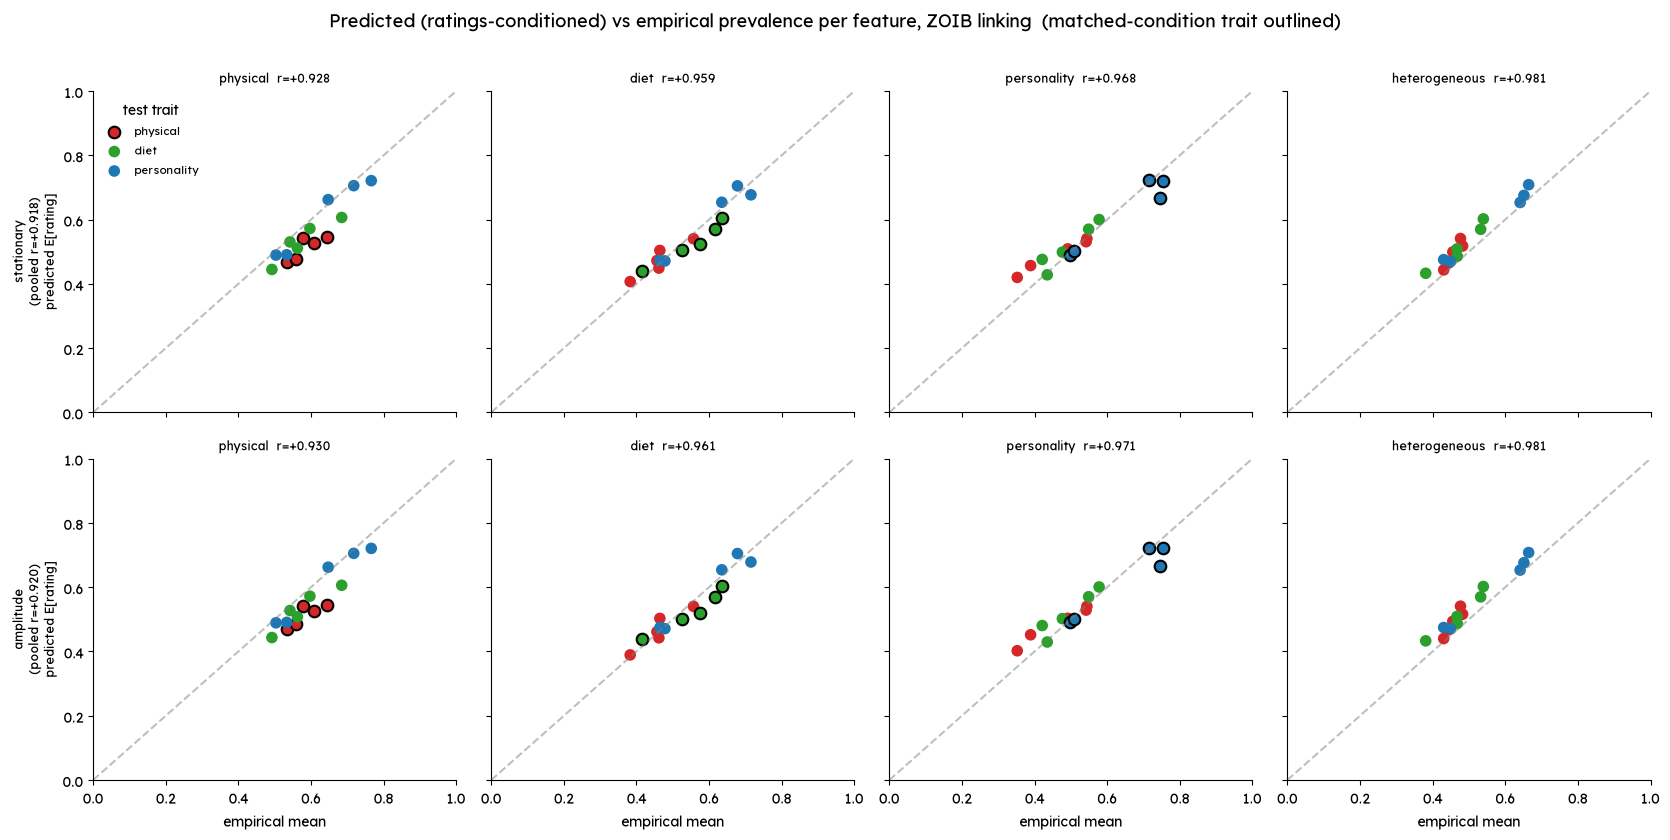

In [9]:
scatter_fig('pred_posterior',
            'Predicted (ratings-conditioned) vs empirical prevalence per feature, ZOIB linking  (matched-condition trait outlined)',
            'predicted-vs-empirical-scatter-comparison.png')

### 5b. Generics-only prediction

saved results/study9-fit-zoib-amp/predicted-vs-empirical-scatter-comparison-ratings-free.png


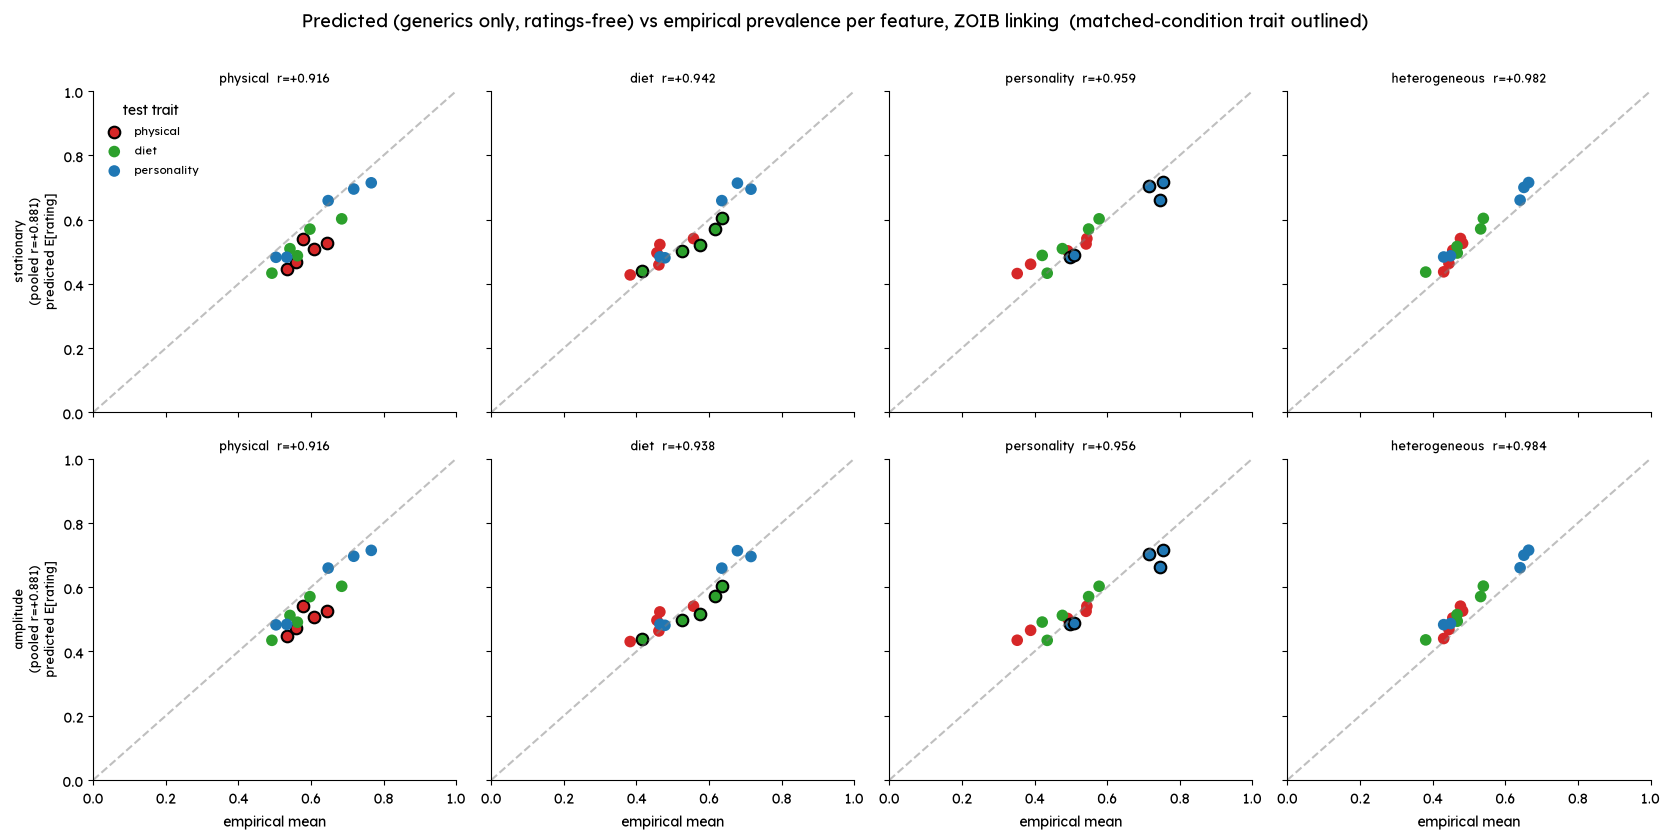

In [10]:
scatter_fig('pred_prior',
            'Predicted (generics only, ratings-free) vs empirical prevalence per feature, ZOIB linking  (matched-condition trait outlined)',
            'predicted-vs-empirical-scatter-comparison-ratings-free.png')